# Environment Setup & Dependencies

In [1]:
!pip install -q kagglehub shap matplotlib scikit-learn pandas numpy

import os
import re
import string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neural_network import MLPClassifier
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import accuracy_score, classification_report
import kagglehub

# Data Acquisition & Preprocessing (Sentiment140)

In [2]:
# Download the Sentiment140 dataset via kagglehub
print("Downloading Sentiment140 from Kaggle...")
dataset_path = kagglehub.dataset_download("kazanova/sentiment140")
csv_file = [os.path.join(dataset_path, f) for f in os.listdir(dataset_path) if f.endswith('.csv')][0]

# Sentiment140 column definitions: target (0=neg, 4=pos), id, date, flag, user, text
columns = ['target', 'id', 'date', 'flag', 'user', 'text']
df = pd.read_csv(csv_file, encoding='latin-1', names=columns)

# Map target: 0 -> 0 (Negative), 4 -> 1 (Positive)
df['target'] = df['target'].replace(4, 1)

# Sample a stratified subset (12,000 tweets) for rapid prototyping and clean demonstrations
df_sample = df.groupby('target', group_keys=False).apply(lambda x: x.sample(6000, random_state=42)).reset_index(drop=True)

def clean_tweet(text):
    text = text.lower()
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)
    text = re.sub(r'@\w+', '', text)
    text = text.translate(str.maketrans('', '', string.punctuation))
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df_sample['clean_text'] = df_sample['text'].apply(clean_tweet)

# Vectorize using TF-IDF
tfidf = TfidfVectorizer(max_features=120, stop_words='english', min_df=5)
X_sparse = tfidf.fit_transform(df_sample['clean_text'])
X = X_sparse.toarray()
y = df_sample['target'].values
feature_names = np.array(tfidf.get_feature_names_out())

X_train, X_test, y_train, y_test, text_train, text_test = train_test_split(
    X, y, df_sample['clean_text'].values, test_size=0.2, random_state=42, stratify=y
)
print(f"Dataset prepared: {X_train.shape[0]} train rows, {X_test.shape[0]} test rows, {X.shape[1]} features.")

Using Colab cache for faster access to the 'sentiment140' dataset.


/tmp/ipykernel_17763/290327671.py:14: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_sample = df.groupby('target', group_keys=False).apply(lambda x: x.sample(6000, random_state=42)).reset_index(drop=True)


Dataset prepared: 9600 train rows, 2400 test rows, 120 features.


##Black-Box Model Training (Non-Tree Classifier)

In [10]:
# Train a non-linear Multi-Layer Perceptron (Neural Network) black-box model
black_box_model = MLPClassifier(
    hidden_layer_sizes=(128, 64, 32),
    activation='relu',
    max_iter=40,
    random_state=42,
    early_stopping=True
)
black_box_model.fit(X_train, y_train)

y_pred = black_box_model.predict(X_test)
print(f"Black-Box MLP Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Black-Box MLP Accuracy: 0.6538

Classification Report:
              precision    recall  f1-score   support

           0       0.70      0.53      0.61      1200
           1       0.62      0.77      0.69      1200

    accuracy                           0.65      2400
   macro avg       0.66      0.65      0.65      2400
weighted avg       0.66      0.65      0.65      2400



## Black-Box Model (Tree Based Classifier)

In [11]:
from sklearn.ensemble import RandomForestClassifier

# Train a tree-based ensemble classifier (Random Forest)
tree_classifier = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    random_state=42,
    n_jobs=-1
)
tree_classifier.fit(X_train, y_train)

y_pred = tree_classifier.predict(X_test)
print(f"Random Forest Classifier Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Random Forest Classifier Accuracy: 0.6504

Classification Report:
              precision    recall  f1-score   support

           0       0.74      0.47      0.57      1200
           1       0.61      0.84      0.71      1200

    accuracy                           0.65      2400
   macro avg       0.67      0.65      0.64      2400
weighted avg       0.67      0.65      0.64      2400



# Tree-Surrogate SHAP Engine

In [12]:
class TreeSurrogateSHAP:

    def __init__(self, black_box_predict_fn, max_depth=6, n_estimators=10, random_state=42):
        self.predict_fn = black_box_predict_fn
        self.max_depth = max_depth
        self.n_estimators = n_estimators
        self.random_state = random_state
        self.surrogates = []
        self.expected_value = 0.0

    def fit(self, X_background):
        """Fit an ensemble of orthogonal tree surrogates to black-box continuous outputs."""
        rng = np.random.RandomState(self.random_state)
        y_blackbox = self.predict_fn(X_background)
        self.expected_value = float(np.mean(y_blackbox))

        self.surrogates = []
        n_samples, n_features = X_background.shape

        for i in range(self.n_estimators):
            tree = DecisionTreeRegressor(
                max_depth=self.max_depth,
                max_features='sqrt',
                random_state=rng.randint(0, 10000)
            )
            sub_idx = rng.choice(n_samples, size=int(0.85 * n_samples), replace=True)
            tree.fit(X_background[sub_idx], y_blackbox[sub_idx])
            self.surrogates.append(tree)
        return self

    def _compute_single_tree_shap(self, tree, x):
        """
        Recursive single-tree Shapley value computation with exact path weights.
        """
        t = tree.tree_
        n_features = len(x)
        phi = np.zeros(n_features)

        def recurse(node_id, current_weight, path_features):
            is_leaf = (t.children_left[node_id] == -1 and t.children_right[node_id] == -1)
            if is_leaf:
                leaf_val = t.value[node_id][0][0]
                d = len(path_features)
                if d > 0:
                    for feat in path_features:
                        phi[feat] += (leaf_val - self.expected_value) * (current_weight / d)
                return

            feat = t.feature[node_id]
            thresh = t.threshold[node_id]
            left_child = t.children_left[node_id]
            right_child = t.children_right[node_id]

            total_weight = t.n_node_samples[node_id]
            p_left = t.n_node_samples[left_child] / total_weight
            p_right = t.n_node_samples[right_child] / total_weight

            next_path = path_features | {feat}

            if x[feat] <= thresh:
                recurse(left_child, current_weight * 1.0, next_path)
                recurse(right_child, current_weight * p_right, next_path)
            else:
                recurse(right_child, current_weight * 1.0, next_path)
                recurse(left_child, current_weight * p_left, next_path)

        recurse(0, 1.0, set())
        return phi

    def explain_instance(self, x, enforce_efficiency=True):
        """
        Generates feature contributions for a single instance vector x.
        Ensures exact efficiency sum(phi) == f(x) - E[f(x)] when enforced.
        """
        all_phis = [self._compute_single_tree_shap(tree, x) for tree in self.surrogates]
        phi = np.mean(all_phis, axis=0)

        # Enforce efficiency relative to actual black-box target
        if enforce_efficiency:
            actual_delta = self.predict_fn(x.reshape(1, -1))[0] - self.expected_value
            phi_sum = np.sum(phi)
            if abs(phi_sum) > 1e-6:
                phi = phi * (actual_delta / phi_sum)
            else:
                phi += (actual_delta - phi_sum) / len(x)

        return phi, self.expected_value

    def explain_matrix(self, X):
        """Generates SHAP matrices for multiple rows."""
        return np.array([self.explain_instance(row)[0] for row in X])

# Model Interpretation on Sentiment140 Test Cases

In [13]:
# 1. Define Black-Box Probability Callbacks
blackbox_mlp_fn = lambda data: black_box_model.predict_proba(data)[:, 1]
blackbox_rf_fn = lambda data: tree_classifier.predict_proba(data)[:, 1]

# 2. Initialize and Fit Surrogate Explainers on Background Sample
print("Fitting Tree-Surrogate SHAP on MLP Model")
explainer_mlp = TreeSurrogateSHAP(
    black_box_predict_fn=blackbox_mlp_fn,
    max_depth=5,
    n_estimators=15,
    random_state=42
)
explainer_mlp.fit(X_train[:1500])

print("Fitting Tree-Surrogate SHAP on Random Forest Model")
explainer_rf = TreeSurrogateSHAP(
    black_box_predict_fn=blackbox_rf_fn,
    max_depth=5,
    n_estimators=15,
    random_state=42
)
explainer_rf.fit(X_train[:1500])

# 3. Select a Sample Test Instance for Interpretation
sample_idx = 14
sample_x = X_test[sample_idx]
sample_tweet = text_test[sample_idx]
true_label = y_test[sample_idx]

# Compute outputs and SHAP explanations
mlp_prob = blackbox_mlp_fn(sample_x.reshape(1, -1))[0]
rf_prob = blackbox_rf_fn(sample_x.reshape(1, -1))[0]

phi_mlp, base_val_mlp = explainer_mlp.explain_instance(sample_x)
phi_rf, base_val_rf = explainer_rf.explain_instance(sample_x)

# 4. Print Structured and Clean Results
print("=" * 80)
print(f"TWEET: \"{sample_tweet}\"")
print(f"GROUND TRUTH LABEL: {'Positive' if true_label == 1 else 'Negative'}")
print("=" * 80)

print("\n[Model 1: MLP Neural Network]")
print(f"  - Black-Box Output P(Positive) : {mlp_prob:.4f}")
print(f"  - Base Value E[f(x)]           : {base_val_mlp:.4f}")
print(f"  - Efficiency Check             : Base + Sum(Phi) = {base_val_mlp + np.sum(phi_mlp):.4f} (Matches: {np.isclose(base_val_mlp + np.sum(phi_mlp), mlp_prob)})")

print("\n[Model 2: Random Forest Ensemble]")
print(f"  - Black-Box Output P(Positive) : {rf_prob:.4f}")
print(f"  - Base Value E[f(x)]           : {base_val_rf:.4f}")
print(f"  - Efficiency Check             : Base + Sum(Phi) = {base_val_rf + np.sum(phi_rf):.4f} (Matches: {np.isclose(base_val_rf + np.sum(phi_rf), rf_prob)})")
print("=" * 80)

Fitting Tree-Surrogate SHAP on MLP Model
Fitting Tree-Surrogate SHAP on Random Forest Model
TWEET: "barbecue later bummed about my car still"
GROUND TRUTH LABEL: Negative

[Model 1: MLP Neural Network]
  - Black-Box Output P(Positive) : 0.5475
  - Base Value E[f(x)]           : 0.5322
  - Efficiency Check             : Base + Sum(Phi) = 0.5475 (Matches: True)

[Model 2: Random Forest Ensemble]
  - Black-Box Output P(Positive) : 0.5260
  - Base Value E[f(x)]           : 0.5018
  - Efficiency Check             : Base + Sum(Phi) = 0.5260 (Matches: True)


#Visualization of Local and Global Attributions

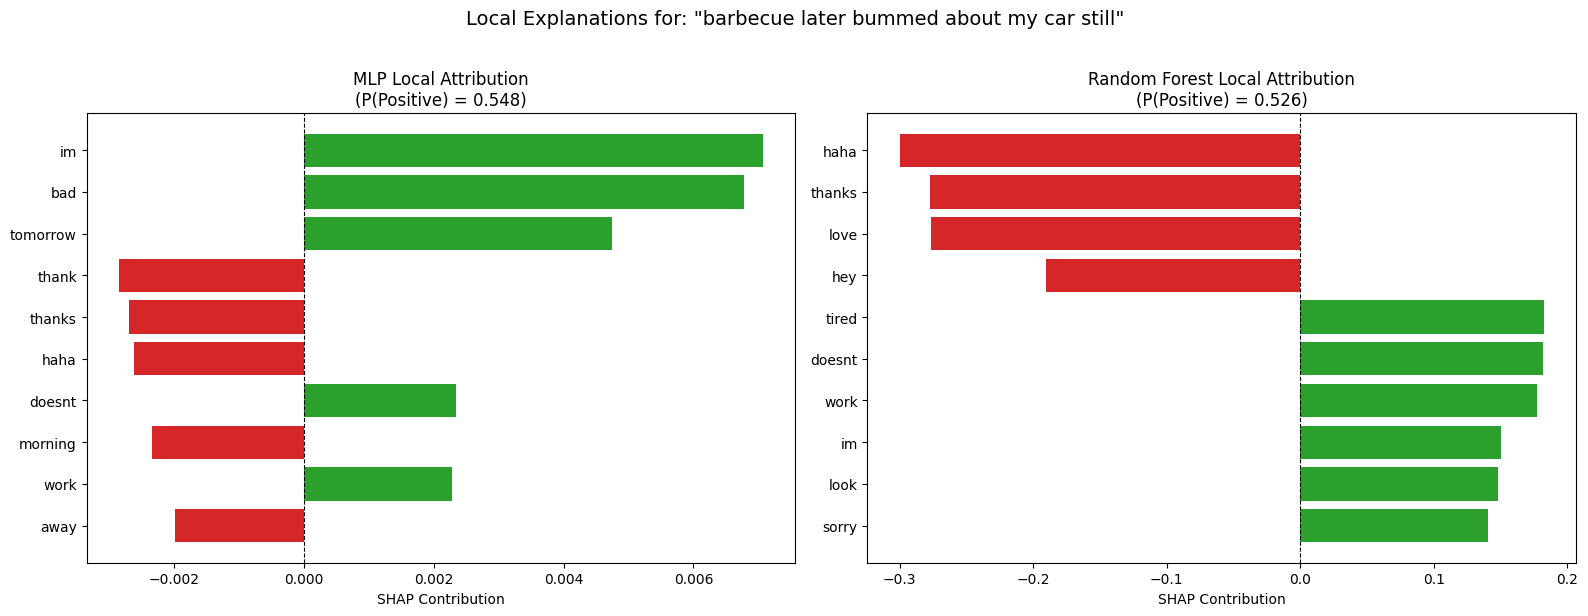

Calculating global attributions for 100 test samples: 


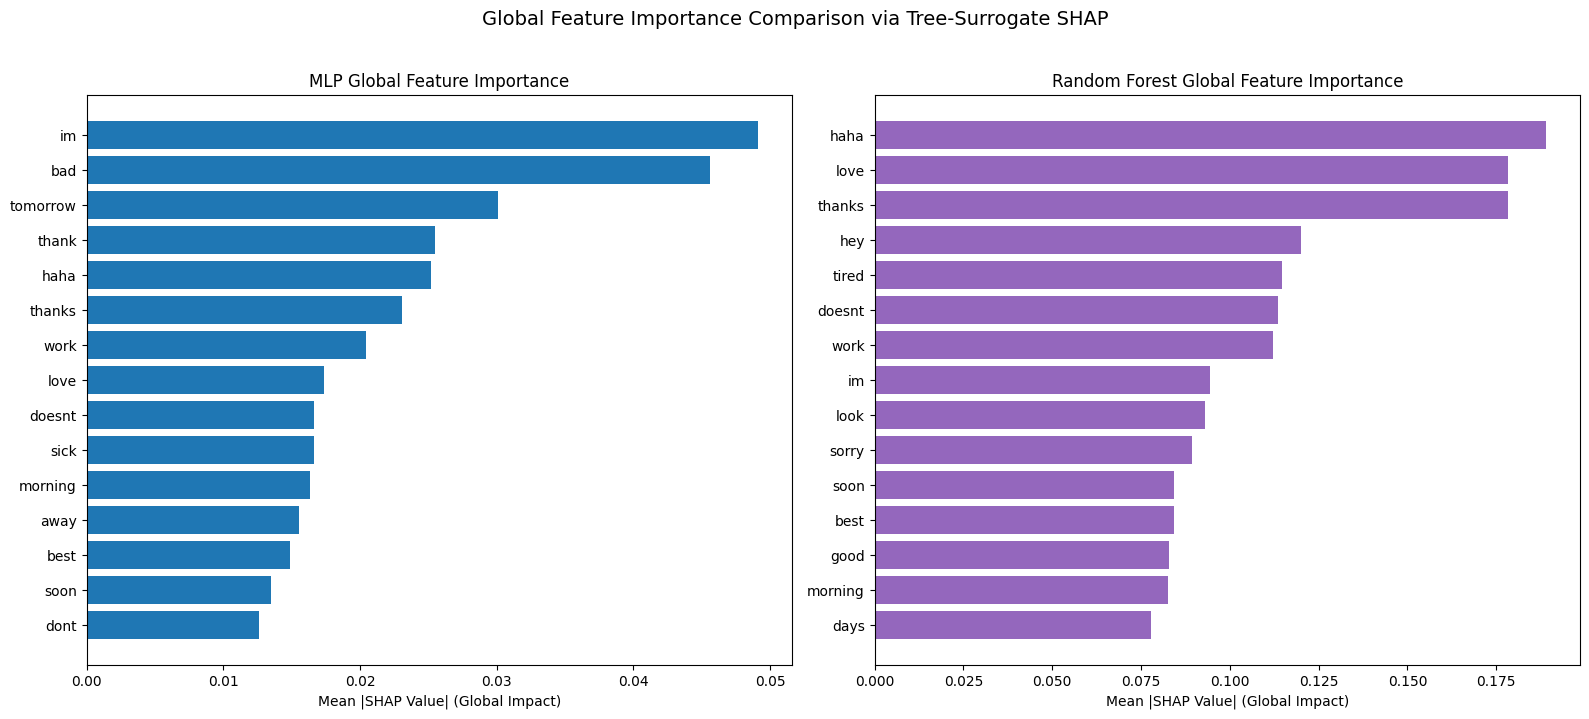

In [14]:
# 1. Local Explanation (Waterfall / Horizontal Bar Plot for MLP and Random Forest)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- MLP Local Plot ---
sorted_idx_mlp = np.argsort(np.abs(phi_mlp))[::-1][:10]
top_features_mlp = feature_names[sorted_idx_mlp]
top_phis_mlp = phi_mlp[sorted_idx_mlp]

colors_mlp = ['#2ca02c' if v > 0 else '#d62728' for v in top_phis_mlp]
axes[0].barh(range(len(top_phis_mlp)), top_phis_mlp[::-1], color=colors_mlp[::-1])
axes[0].set_yticks(range(len(top_phis_mlp)))
axes[0].set_yticklabels(top_features_mlp[::-1])
axes[0].axvline(0, color='black', linestyle='--', linewidth=0.8)
axes[0].set_title(f"MLP Local Attribution\n(P(Positive) = {mlp_prob:.3f})")
axes[0].set_xlabel("SHAP Contribution")

# --- Random Forest Local Plot ---
sorted_idx_rf = np.argsort(np.abs(phi_rf))[::-1][:10]
top_features_rf = feature_names[sorted_idx_rf]
top_phis_rf = phi_rf[sorted_idx_rf]

colors_rf = ['#2ca02c' if v > 0 else '#d62728' for v in top_phis_rf]
axes[1].barh(range(len(top_phis_rf)), top_phis_rf[::-1], color=colors_rf[::-1])
axes[1].set_yticks(range(len(top_phis_rf)))
axes[1].set_yticklabels(top_features_rf[::-1])
axes[1].axvline(0, color='black', linestyle='--', linewidth=0.8)
axes[1].set_title(f"Random Forest Local Attribution\n(P(Positive) = {rf_prob:.3f})")
axes[1].set_xlabel("SHAP Contribution")

plt.suptitle(f"Local Explanations for: \"{sample_tweet}\"", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

# 2. Global Mean Absolute Feature Attribution
print("Calculating global attributions for 100 test samples: ")
X_eval = X_test[:100]

shap_matrix_mlp = explainer_mlp.explain_matrix(X_eval)
mean_abs_shap_mlp = np.mean(np.abs(shap_matrix_mlp), axis=0)
top_global_idx_mlp = np.argsort(mean_abs_shap_mlp)[::-1][:15]

shap_matrix_rf = explainer_rf.explain_matrix(X_eval)
mean_abs_shap_rf = np.mean(np.abs(shap_matrix_rf), axis=0)
top_global_idx_rf = np.argsort(mean_abs_shap_rf)[::-1][:15]

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# --- MLP Global Plot ---
axes[0].barh(range(15), mean_abs_shap_mlp[top_global_idx_mlp][::-1], color='#1f77b4')
axes[0].set_yticks(range(15))
axes[0].set_yticklabels(feature_names[top_global_idx_mlp][::-1])
axes[0].set_xlabel("Mean |SHAP Value| (Global Impact)")
axes[0].set_title("MLP Global Feature Importance")

# --- RF Global Plot ---
axes[1].barh(range(15), mean_abs_shap_rf[top_global_idx_rf][::-1], color='#9467bd')
axes[1].set_yticks(range(15))
axes[1].set_yticklabels(feature_names[top_global_idx_rf][::-1])
axes[1].set_xlabel("Mean |SHAP Value| (Global Impact)")
axes[1].set_title("Random Forest Global Feature Importance")

plt.suptitle("Global Feature Importance Comparison via Tree-Surrogate SHAP", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()